# Robustness check with 10 m LiDAR metrics
---
The ring analysis repeated on the 10 m raster `metriche_z_raster.tiff` (mean height, vertical SD and 90th percentile) for the reduced mound set and the controls.

Split from the former `experimentation.ipynb`.

In [ ]:
# --- Project paths ------------------------------------------------------------
# Modules are in src/, data in data/, results in results/, figures in figures/.
# Works no matter from which folder the notebook is started.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(ROOT / "src"))

from paths import data, DATA_RAW, DATA_PROCESSED, RESULTS, FIGURES
import helpers
helpers.FIG_DIR = FIGURES / "05_robustness_10m_lidar"     # save_fig() writes here
helpers.FIG_DIR.mkdir(parents=True, exist_ok=True)

In [61]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from cycler import cycler
from kiln_ring_analysis import kiln_ring_analysis, DEFAULTS as ANALYSIS_DEFAULTS
from plot_kiln_rings import plot_kiln_rings, DEFAULTS as PLOT_DEFAULTS
from helpers import save_fig


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


For a constant look, we define a colour scheme to be used for all graphs:

In [62]:
COLSCHEME = {
       "ember":  ["#FDBE85", "#F68C3A", "#D9541A"],
       "forest": ["#A8DDB5", "#4DAF6E", "#23794A"],
       "smoke":  ["#A6CEE3", "#4A90C8", "#2563A0"]
       }

plt.rcParams["axes.prop_cycle"] = cycler(color=[COLSCHEME["smoke"][2], COLSCHEME["ember"][2],
                                                COLSCHEME["forest"][2], COLSCHEME["smoke"][1],
                                                COLSCHEME["ember"][1], COLSCHEME["forest"][1]])

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "pdf.fonttype": 42,
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

The setup cells below (imports, colour scheme and helper functions) are the same as in the other analysis notebooks, so this notebook runs on its own.

### Plot function
Here, we define a function for plotting the raw outpur of the analysis. It plots each ray of each kiln. The function includes the possibility to smooth the output of each ray with a moving window. This is done to reduce the impact that noise has on the visualisation, hiding the trends we are looking for.

In [64]:
def plot_raw_rays(samples: pd.DataFrame, rings: list, window_size=1, l_alpha=0.1, st_dev=False, color=COLSCHEME, ctrl_samples=None, y_label=None):
    samples = samples.sort_values(["kiln_id", "ray", "distance"])
    samples["smooth"] = (samples.groupby(["kiln_id", "ray"])["value"].transform(lambda v: v.rolling(window_size, center=True, min_periods=1).mean()))

    def smooth(s):
        s = s.sort_values(["kiln_id", "ray", "distance"]).copy()
        s["smooth"] = s.groupby(["kiln_id", "ray"])["value"].transform(
            lambda v: v.rolling(window_size, center=True, min_periods=1).mean())
        return s

    samples = smooth(samples)
    fig, ax = plt.subplots(figsize=(6.3,3))

    # all lines
    for _, line in samples.groupby(["kiln_id", "ray"]):
        ax.plot(line["distance"], line["smooth"], color=color["forest"][1], alpha=l_alpha, lw=0.8)

    # mean ± 1 SD per distance, for the kilns and (optionally) the controls
    groups = [("Charcoal mounds", samples, color["ember"])]
    if ctrl_samples is not None:
        groups.append(("Controls", smooth(ctrl_samples), color["smoke"]))
    for label, s, c in groups:
        per_dist = s.groupby("distance")["smooth"]
        m, sd = per_dist.mean(), per_dist.std()
        ax.plot(m.index, m + sd, color=c[2], lw=0.8, ls="--", label=f"{label}: mean ± 1 SD")
        ax.plot(m.index, m - sd, color=c[2], lw=0.8, ls="--")
        ax.plot(m.index, m, color=c[2], lw=1.5, label=f"{label}: mean")

    # ring interval boundaries
    for _, outer in rings[:-1]:
        ax.axvline(outer, color="black", lw=0.6, ls=":", alpha=0.6)

    ax.set_xlim(0,rings[-1][-1])
    ax.set_ylim(0, max(samples["smooth"])+2)
    ax.set_xlabel("Distance from mound (m)")
    if y_label:
        ax.set_ylabel(y_label)
    elif window_size == 1:
        ax.set_ylabel(f"Canopy height (m)")
    else:
        ax.set_ylabel(f"Smoothed canopy height (m) (window={window_size})")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig

In [91]:
def ring_sd(out):
    s = out["samples"]
    s = s[s["ring_index"] >= 0]
    min_valid = out["params"]["min_valid"]

    def sd(g):
        if g["valid"].mean() < min_valid:
            return np.nan
        v = g.loc[g["valid"], "value"].to_numpy()
        w = g.loc[g["valid"], "weight"].to_numpy()
        m = np.sum(w * v) / np.sum(w)
        return np.sqrt(np.sum(w * (v - m) ** 2) / np.sum(w))

    table = s.groupby(["kiln_id", "ring_index"]).apply(sd, include_groups=False).unstack("ring_index")
    labels = s.drop_duplicates("ring_index").set_index("ring_index")["ring"]
    return table.rename(columns=labels)   # columns in ring order, labelled "0-6" etc.

In [92]:
import geopandas as gpd

def ring_stat(out, stat):
    """One value per site and ring; stat(values, weights) -> number."""
    s = out["samples"]
    s = s[s["ring_index"] >= 0]
    min_valid = out["params"]["min_valid"]

    def f(g):
        if g["valid"].mean() < min_valid:
            return np.nan
        g = g[g["valid"]]
        return stat(g["value"].to_numpy(), g["weight"].to_numpy())

    table = s.groupby(["kiln_id", "ring_index"]).apply(f, include_groups=False).unstack("ring_index")
    labels = s.drop_duplicates("ring_index").set_index("ring_index")["ring"]
    return table.rename(columns=labels)


def w_mean(v, w):
    return np.average(v, weights=w)

def w_sd(v, w):
    return np.sqrt(np.average((v - w_mean(v, w)) ** 2, weights=w))

def w_pct(v, w, q):
    """Weighted percentile; with all weights 1 the ordinary (lower) percentile."""
    o = np.argsort(v)
    cum = np.cumsum(w[o])
    return v[o][np.searchsorted(cum, q / 100 * cum[-1])]

GAP_HEIGHT = 2   # m

STATS = {
    "Mean canopy height (m)": w_mean,
    "Within-ring SD (m)":     w_sd,
    "Gap share":              lambda v, w: np.sum(w * (v < GAP_HEIGHT)) / np.sum(w),
    "P90 height (m)":         lambda v, w: w_pct(v, w, 90),
    "CV":                     lambda v, w: np.nan if w_mean(v, w) < 2 else w_sd(v, w) / w_mean(v, w),
}


CTRL_ID  = "ID_PAROLINI"   # unique ID per control (the id_column used for the controls run)
KILN_REF = "kiln_id"      # column in controls_2056.gpkg naming the kiln each control belongs to

# Which kiln each control belongs to
ctrl = gpd.read_file(data("controls_2056.gpkg"))
pair = ctrl.set_index(ctrl[CTRL_ID].astype(str))[KILN_REF].astype(str)

def per_kiln(table, is_control):
    """Index as strings; for controls, average all controls of the same kiln."""
    table = table.copy()
    table.index = table.index.astype(str)
    if is_control:
        table = table.groupby(pair.reindex(table.index).to_numpy()).mean()
    return table

In [80]:
from scipy.stats import wilcoxon, ttest_1samp, friedmanchisquare

def paired_tests(diff, raw=None, unit="m"):
    """Tests on paired differences (control − kiln): one row per kiln, one column per ring.
    raw: optional {label: table} of the raw values, to test the change across rings."""
    rows = []
    for c in diff:
        x = diff[c].dropna()
        ci = ttest_1samp(x, 0).confidence_interval(0.95)
        rows.append({"ring": c, "n": len(x), "mean diff": x.mean(),
                     "95% CI low": ci.low, "95% CI high": ci.high,
                     "Wilcoxon p": wilcoxon(x).pvalue})
    tests = pd.DataFrame(rows).set_index("ring")

    # Holm correction for the per-ring tests
    p = tests["Wilcoxon p"].to_numpy()
    order = np.argsort(p)
    adj = np.minimum(1, np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]))
    tests.loc[tests.index[order], "Holm p"] = adj
    print(tests.round(3))

    # Overall: each kiln's difference averaged over all rings, one test
    overall = diff.mean(axis=1).dropna()
    ci = ttest_1samp(overall, 0).confidence_interval(0.95)
    print(f"\nAll rings together: mean diff = {overall.mean():.3f} {unit} "
          f"(95% CI {ci.low:.3f} to {ci.high:.3f}), "
          f"Wilcoxon p = {wilcoxon(overall).pvalue:.3f} (n = {len(overall)})")

    # Does the paired difference change across rings?
    d = diff.dropna()
    print(f"Paired difference across rings: Friedman p = "
          f"{friedmanchisquare(*[d[c] for c in d]).pvalue:.3f} (n = {len(d)})")

    # Do the raw values change across rings? (method artefact for the SD)
    for label, t in (raw or {}).items():
        t = t.dropna()
        print(f"Raw values across rings, {label}: Friedman p = "
              f"{friedmanchisquare(*[t[c] for c in t]).pvalue:.4f} (n = {len(t)})")
    return tests

## 10 Tif with better vertical resolution

In [82]:
from kiln_ring_analysis import kiln_ring_analysis
from plot_kiln_rings import plot_kiln_rings
from helpers import save_fig

In [83]:
bands = {2: "mean", 3: "vsd", 26: "p90"}
rings = [(0, 5), (5, 15), (15, 25), (25, 35)]

out_kiln_red_10 = {}
for band, name in bands.items():
    out_kiln_red_10[name] = kiln_ring_analysis({
        "tif": data("metriche_z_raster.tiff"),
        "gpkg": data("kohlmeiler_2056_reduced.gpkg"),
        "band": band,
        "n_rays": 8,
        "step": 10,
        "include_centre": True,
        "rings": rings,
        "comment": f"band{band}_{name}",    # separate results folder per band
        "out_prefix": f"dem_{name}",        # separate file names per band
    })

out_kiln_red_10["p90"]["summary"]

Raster:        metriche_z_raster.tiff
Band:          2 of 36 (zmean)
CRS:           EPSG:2056
Pixel size:    10.0 x 10.0 m
Nodata value:  nan
Kilns:         60 from kohlmeiler_2056_reduced.gpkg
Rays:          8 (every 45°), sample every 10 m up to 35 m
Weighted:      False
Centre used:   True
Samples per ring (identical for every kiln):
       0-5     m: 1 samples
       5-15    m: 8 samples
      15-25    m: 8 samples
      25-35    m: 8 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-5 m  5-15 m  15-25 m  25-35 m
count   60.00   60.00    60.00    60.00
median   3.74    3.65     3.76     3.72
mean     4.60    4.54     4.55     4.53
std      2.63    2.45     2.43     2.47
min      1.01    1.28     1.30     1.55
25%      2.87    2.93     3.00     3.00
50%      3.74    3.65     3.76     3.72
75%      5.56    5.33     5.17     4.70
max     12.94   13.12    12.79    11.44

Saved: results/metriche_z_raster_rays8_step10_rings0-5_5-15_15-25_25-35_band2_me

,0-5 m,5-15 m,15-25 m,25-35 m
count,60.000000,60.000000,60.000000,60.000000
median,9.212500,9.471625,9.464750,9.497562
mean,10.976767,10.765925,10.689362,10.626694
std,4.201295,3.995180,3.877182,3.878720
min,2.840000,3.268500,3.779375,4.195500
25%,8.396000,7.893219,8.141656,8.210156
50%,9.212500,9.471625,9.464750,9.497562
75%,13.405000,12.691687,12.428562,11.934938
max,21.336000,22.513625,21.664500,20.754625


60 RCM, rings: 0-5 m, 5-15 m, 15-25 m, 25-35 m
RCMs with at least one empty ring: 0
Saved results/metriche_z_raster_rays8_step10_rings0-5_5-15_15-25_25-35_band2_mean_reduced/dem_mean_reduced_rings_mean_plot.png


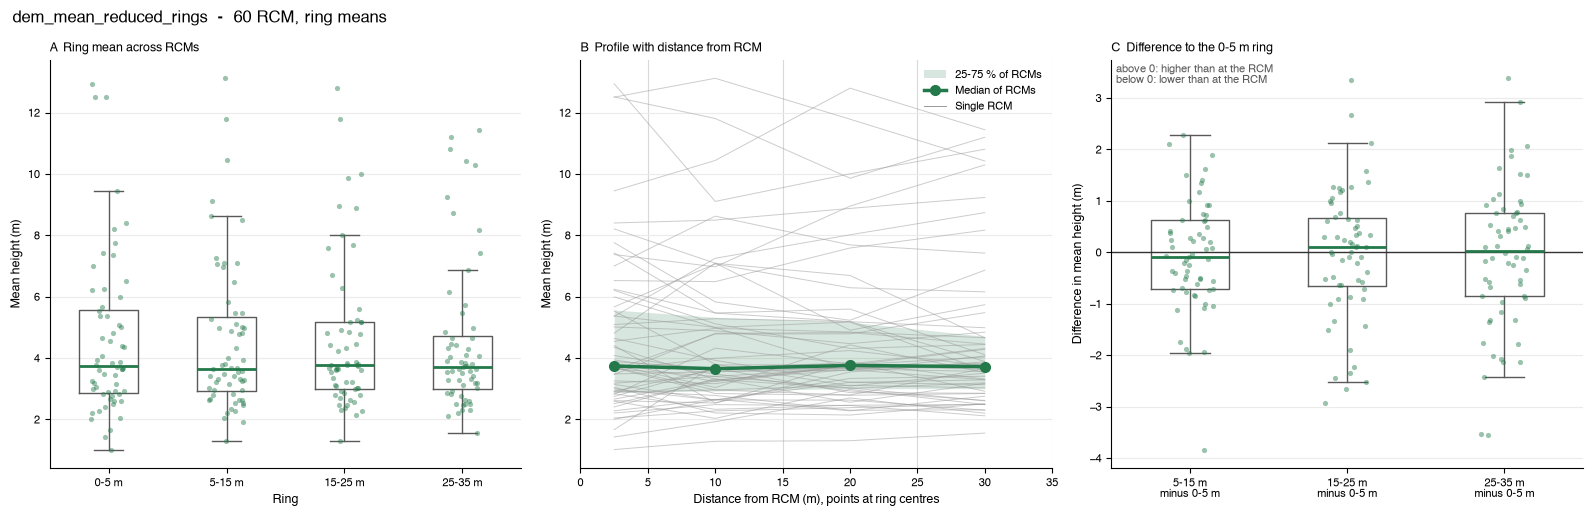

60 RCM, rings: 0-5 m, 5-15 m, 15-25 m, 25-35 m
RCMs with at least one empty ring: 0
Saved results/metriche_z_raster_rays8_step10_rings0-5_5-15_15-25_25-35_band3_vsd_reduced/dem_vsd_reduced_rings_mean_plot.png


<Figure size 640x480 with 0 Axes>

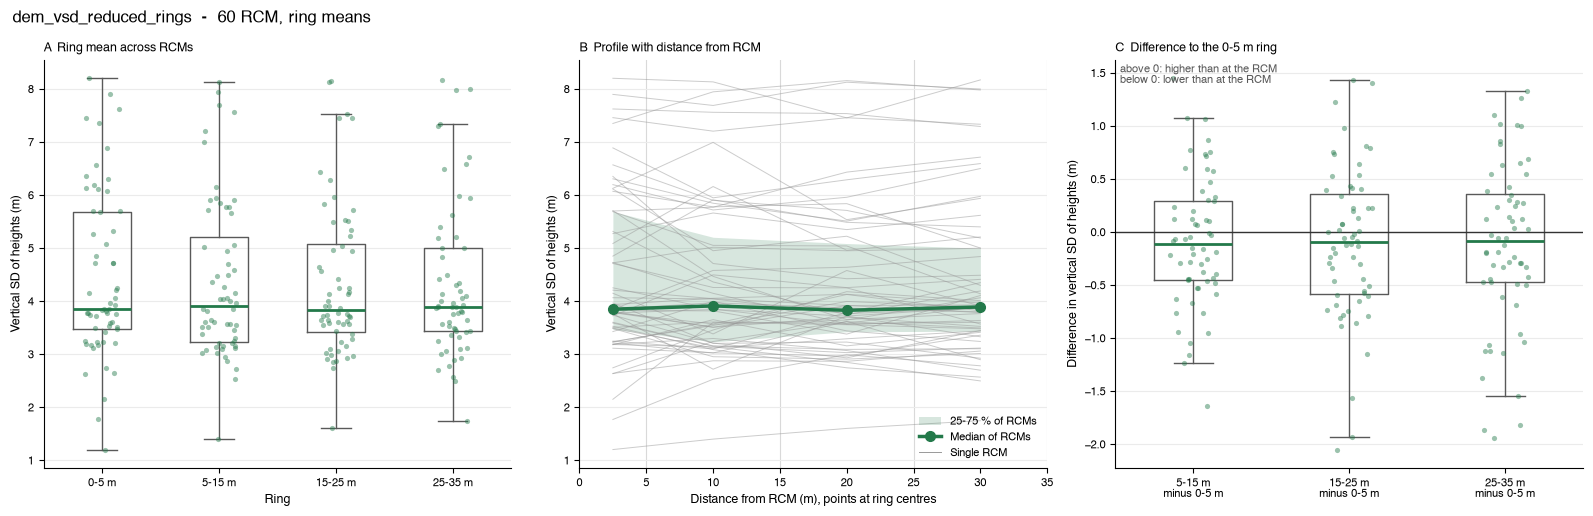

60 RCM, rings: 0-5 m, 5-15 m, 15-25 m, 25-35 m
RCMs with at least one empty ring: 0
Saved results/metriche_z_raster_rays8_step10_rings0-5_5-15_15-25_25-35_band26_p90_reduced/dem_p90_reduced_rings_mean_plot.png


<Figure size 640x480 with 0 Axes>

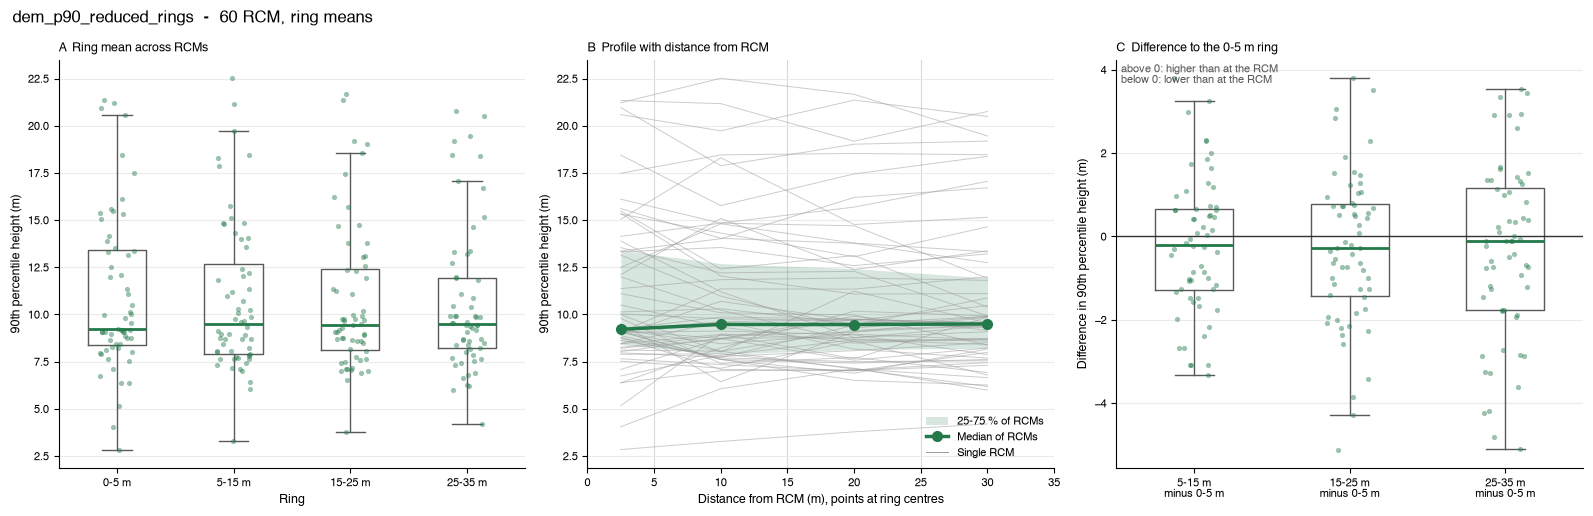

<Figure size 640x480 with 0 Axes>

In [84]:
y_labels = {"mean": "Mean height (m)",
            "vsd": "Vertical SD of heights (m)",
            "p90": "90th percentile height (m)"}

for name, res in out_kiln_red_10.items():
    plot_kiln_rings({
        "rings_csv": res["files"]["rings"],
        "y_label": y_labels[name],
    })
    save_fig(f"10m_kiln_red_{name}")

In [85]:
bands = {2: "mean", 3: "vsd", 26: "p90"}
rings = [(0, 5), (5, 15), (15, 25), (25, 35)]

out_controls_10 = {}
for band, name in bands.items():
    out_controls_10[name] = kiln_ring_analysis({
        "tif": data("metriche_z_raster.tiff"),
        "gpkg": data("controls_2056_36_150.gpkg"),
        "band": band,
        "n_rays": 8,
        "step": 10,
        "include_centre": True,
        "rings": rings,
        "comment": f"band{band}_{name}",   # "_controls" is added automatically
        "out_prefix": f"dem_{name}",        # separate file names per band
    })

out_controls_10["p90"]["summary"]

Raster:        metriche_z_raster.tiff
Band:          2 of 36 (zmean)
CRS:           EPSG:2056
Pixel size:    10.0 x 10.0 m
Nodata value:  nan
Kilns:         170 from controls_2056_36_150.gpkg
Rays:          8 (every 45°), sample every 10 m up to 35 m
Weighted:      False
Centre used:   True
Samples per ring (identical for every kiln):
       0-5     m: 1 samples
       5-15    m: 8 samples
      15-25    m: 8 samples
      25-35    m: 8 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
         0-5 m  5-15 m  15-25 m  25-35 m
count   170.00  170.00   170.00   170.00
median    3.66    3.75     3.52     3.52
mean      4.34    4.28     4.38     4.35
std       2.92    2.44     2.50     2.46
min       0.47    0.74     0.73     0.66
25%       2.52    2.61     2.75     2.74
50%       3.66    3.75     3.52     3.52
75%       5.14    4.96     5.05     4.79
max      18.60   16.68    16.72    15.49

Saved: results/metriche_z_raster_rays8_step10_rings0-5_5-15_15-25_25-35_

,0-5 m,5-15 m,15-25 m,25-35 m
count,170.000000,170.000000,170.000000,170.000000
median,9.524000,9.568812,8.993875,9.050813
mean,10.295712,10.394083,10.407854,10.351446
std,4.817221,4.131498,4.070807,4.014367
min,0.890000,2.470875,2.421625,2.150625
25%,7.139750,7.794469,7.743531,7.696438
50%,9.524000,9.568812,8.993875,9.050813
75%,12.010000,11.903063,11.959187,11.597313
max,28.153000,26.318375,26.802750,25.099000


170 RCM, rings: 0-5 m, 5-15 m, 15-25 m, 25-35 m
RCMs with at least one empty ring: 0
Saved results/metriche_z_raster_rays8_step10_rings0-5_5-15_15-25_25-35_band2_mean_controls_controls/dem_mean_controls_rings_mean_plot.png


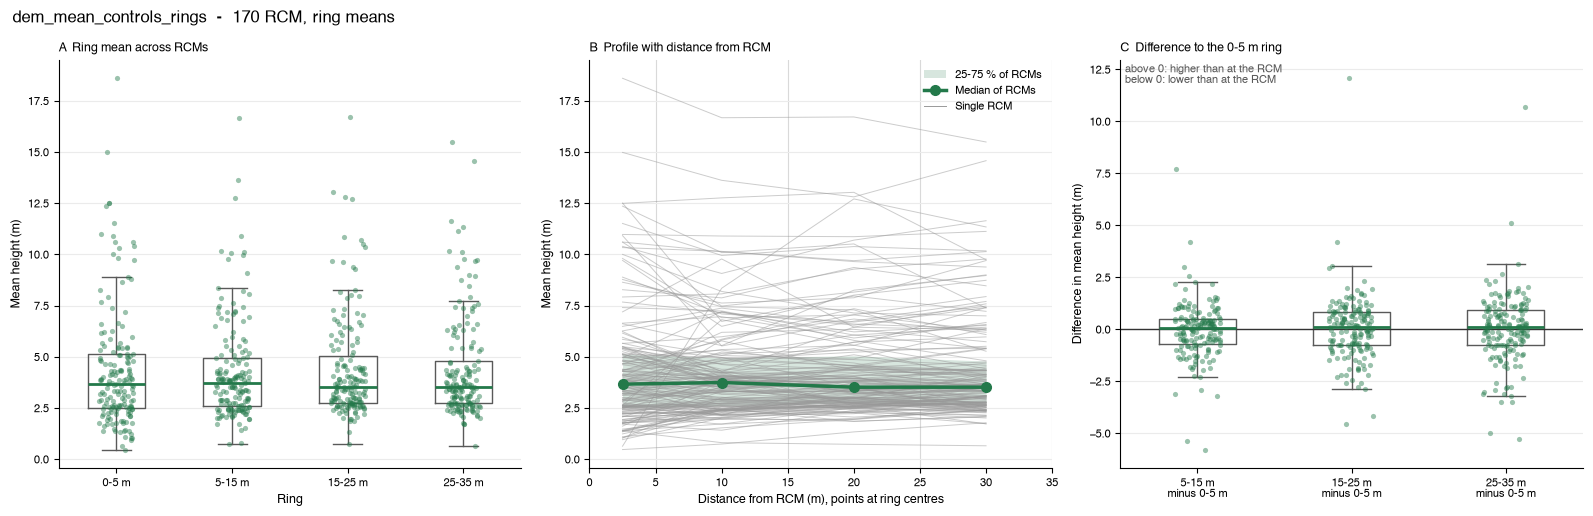

170 RCM, rings: 0-5 m, 5-15 m, 15-25 m, 25-35 m
RCMs with at least one empty ring: 0
Saved results/metriche_z_raster_rays8_step10_rings0-5_5-15_15-25_25-35_band3_vsd_controls_controls/dem_vsd_controls_rings_mean_plot.png


<Figure size 640x480 with 0 Axes>

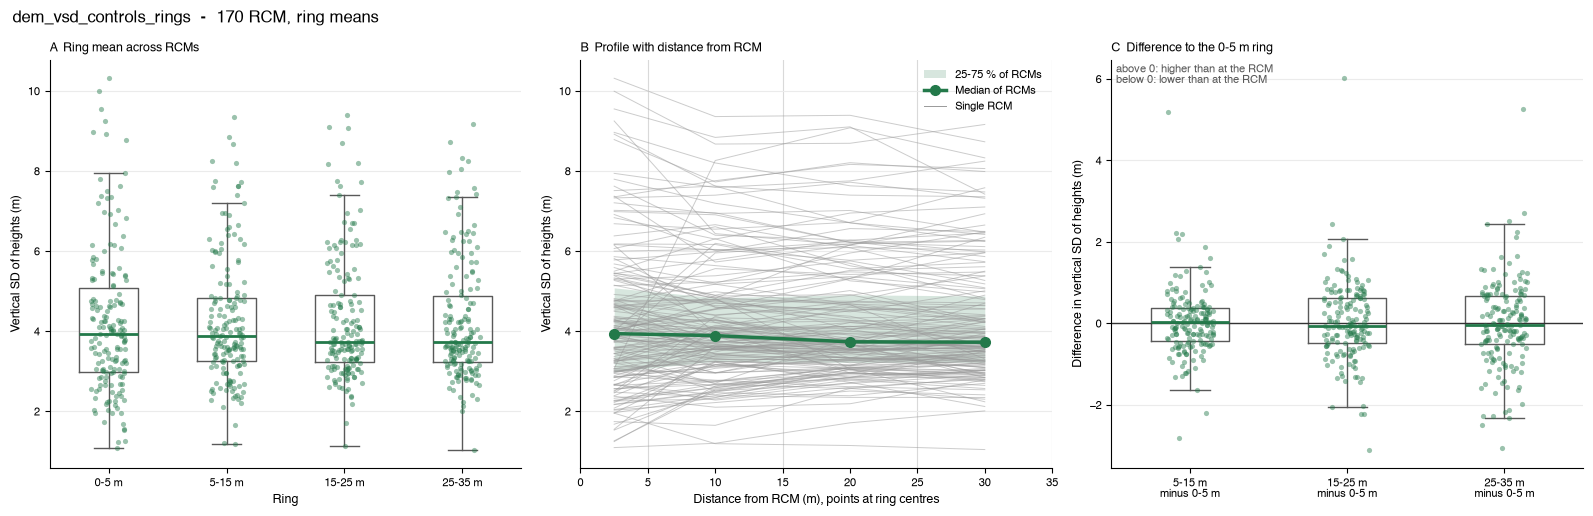

170 RCM, rings: 0-5 m, 5-15 m, 15-25 m, 25-35 m
RCMs with at least one empty ring: 0
Saved results/metriche_z_raster_rays8_step10_rings0-5_5-15_15-25_25-35_band26_p90_controls_controls/dem_p90_controls_rings_mean_plot.png


<Figure size 640x480 with 0 Axes>

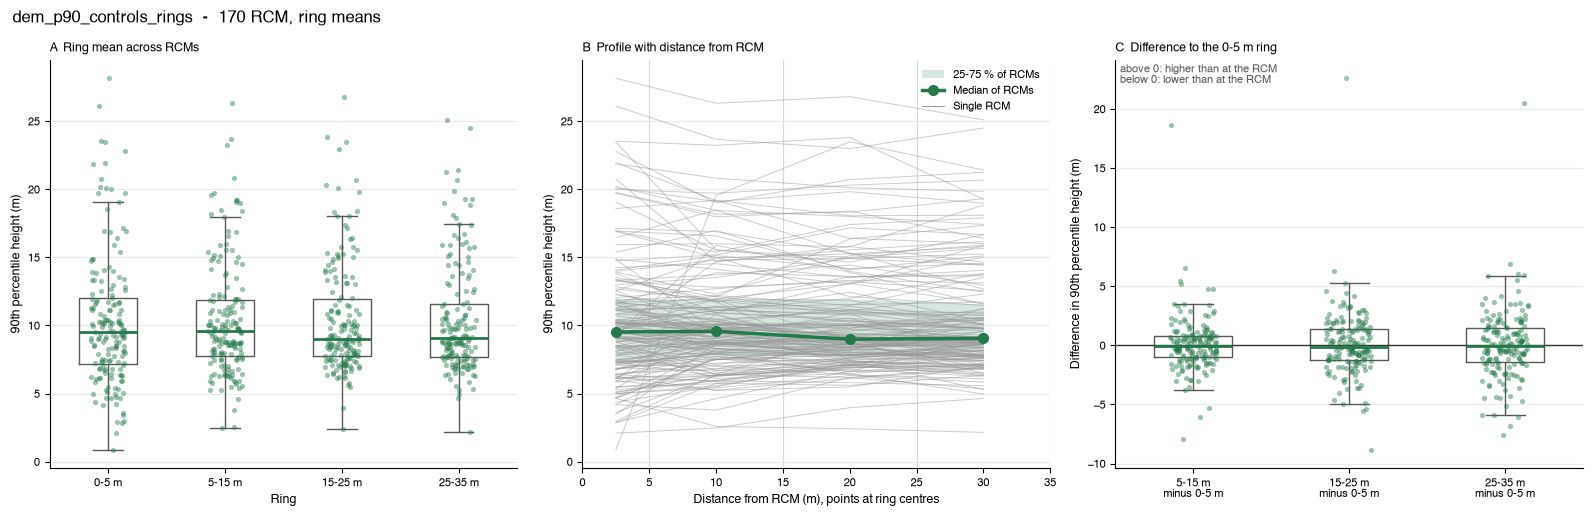

<Figure size 640x480 with 0 Axes>

In [86]:
y_labels = {"mean": "Mean height (m)",
            "vsd": "Vertical SD of heights (m)",
            "p90": "90th percentile height (m)"}

for name, res in out_controls_10.items():
    plot_kiln_rings({
        "rings_csv": res["files"]["rings"],
        "y_label": y_labels[name],
    })
    save_fig(f"10m_controls_{name}")



=== Mean height (m) ===
        n  mean diff  95% CI low  95% CI high  Wilcoxon p  Holm p
ring                                                             
0-5    58     -0.266      -0.725        0.194       0.095   0.381
5-15   58     -0.145      -0.585        0.295       0.410   0.893
15-25  58     -0.120      -0.539        0.298       0.316   0.893
25-35  58     -0.120      -0.472        0.233       0.298   0.893

All rings together: mean diff = -0.163 m (95% CI -0.534 to 0.209), Wilcoxon p = 0.165 (n = 58)
Paired difference across rings: Friedman p = 0.704 (n = 58)
Raw values across rings, mounds: Friedman p = 0.9319 (n = 60)
Raw values across rings, controls: Friedman p = 0.2950 (n = 170)

=== Vertical SD (m) ===
        n  mean diff  95% CI low  95% CI high  Wilcoxon p  Holm p
ring                                                             
0-5    58     -0.199      -0.489        0.091       0.144   0.578
5-15   58     -0.021      -0.293        0.251       0.679   1.000
15-25  5

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


[PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/paired_diff_10m_bands.png'),
 PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/paired_diff_10m_bands.pdf')]

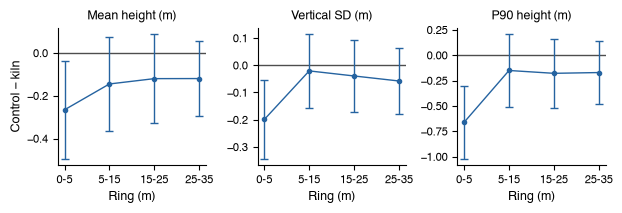

In [87]:
import geopandas as gpd

# Pairing for the controls used in the 10 m runs
ctrl_150 = gpd.read_file(data("controls_2056_36_150.gpkg"))
pair_150 = ctrl_150.set_index(ctrl_150["ID_PAROLINI"].astype(str))["kiln_id"].astype(str)

def paired_diff_10(stat, kiln_out, ctrl_out, pair):
    """Control minus its kiln, one row per kiln, one column per ring."""
    k = ring_stat(kiln_out, stat)
    k.index = k.index.astype(str)
    c = ring_stat(ctrl_out, stat)
    c.index = c.index.astype(str)
    c = c.groupby(pair.reindex(c.index).to_numpy()).mean()   # average the controls of each kiln
    ids = k.index.intersection(c.index)
    return c.loc[ids] - k.loc[ids]

band_labels = {"mean": "Mean height (m)",
               "vsd":  "Vertical SD (m)",
               "p90":  "P90 height (m)"}

results_10 = {}
fig, axes = plt.subplots(1, 3, figsize=(6.3, 2.2))
for ax, (name, label) in zip(axes, band_labels.items()):
    diff = paired_diff_10(w_mean, out_kiln_red_10[name], out_controls_10[name], pair_150)

    ax.axhline(0, color="0.3", lw=1)
    ax.errorbar(diff.columns, diff.mean(), yerr=diff.std() / np.sqrt(diff.count()),
                marker="o", markersize=3, lw=1, capsize=3, color=COLSCHEME["smoke"][2])
    ax.set_title(label)
    ax.set_xlabel("Ring (m)")
    ax.spines[["top", "right"]].set_visible(False)

    print(f"=== {label} ===")
    results_10[name] = paired_tests(diff, raw={"mounds": ring_stat(out_kiln_red_10[name], w_mean),
                                               "controls": ring_stat(out_controls_10[name], w_mean)})
    print()

axes[0].set_ylabel("Control − kiln")
plt.tight_layout()
save_fig("paired_diff_10m_bands", fig=fig)

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


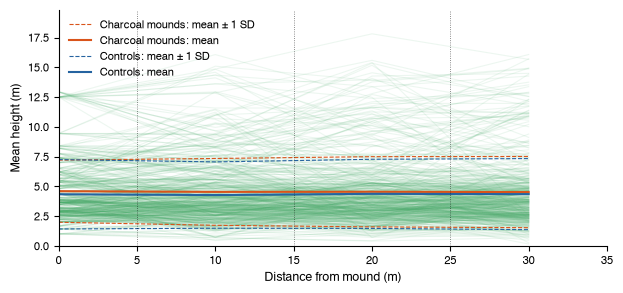

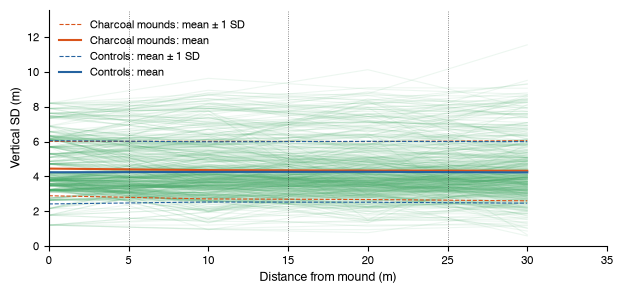

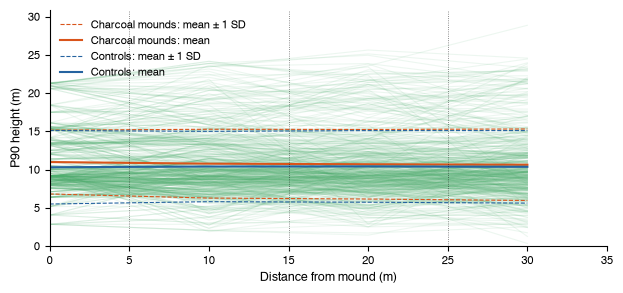

In [88]:
def centre_on_rays(s):
    """Copy each kiln's centre sample (ray -1) into every ray at distance 0."""
    centre = s[s["ray"] == -1]
    rays = s.loc[s["ray"] >= 0, "ray"].unique()
    return pd.concat([s[s["ray"] >= 0]] + [centre.assign(ray=r) for r in rays],
                     ignore_index=True)

rings = [(0, 5), (5, 15), (15, 25), (25, 35)]

band_labels = {"mean": "Mean height (m)",
               "vsd":  "Vertical SD (m)",
               "p90":  "P90 height (m)"}

for name, label in band_labels.items():
    fig = plot_raw_rays(centre_on_rays(out_kiln_red_10[name]["samples"]), rings,
                        window_size=1, l_alpha=0.1,
                        ctrl_samples=centre_on_rays(out_controls_10[name]["samples"]),
                        y_label=label)
    save_fig(f"raw_rays_10m_{name}", fig=fig)